# 07 — Initial placement vs. actual gameplay outcomes
The predictors describe only the first two placement rounds. Actual winner, final VP, and observed third-settlement timing are outcomes only. All games use RandomPlayer; conclusions are associations, not causal or human-player results.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from outcome_extraction import extract
from outcome_prediction import compare
OUT=Path("processed_data_5000")
CHARTS=Path("charts/outcomes_5000")
CHARTS.mkdir(parents=True,exist_ok=True)
o=extract(Path('data_5000'))
o.to_csv(OUT/"actual_outcomes.csv",index=False)
f=pd.read_csv(OUT/"starting_advantage.csv")
d=f.merge(o,on=["Game_ID","Player","Player_Number"],validate="one_to_one")
assert len(d)==len(f)==len(o)
assert d.loc[d.Completed_Game.eq(1)].groupby("Game_ID").Won.sum().eq(1).all()
d["Built_Third"]=d.Actual_Turns_To_Third.notna()
d.to_csv(OUT/"initial_vs_outcome.csv",index=False)
display(d.head())

,Game_ID,Player,Placement_Order,Settlement_1_Score,Settlement_2_Score,Wood_Production,Brick_Production,Sheep_Production,Wheat_Production,Ore_Production,...,Prob_Turn_20,Prob_Turn_40,Final_VP,Completed_Game,Won,Actual_Turns_To_Third,Actual_Rolls_To_Third,Observed_Personal_Rolls,Game_Total_Rolls,Built_Third
0,000a8611-8efa-43ef-aa17-2b695845f514,ORANGE,1,6,3,0,0,3,5,1,...,0.467448,0.999895,8,1,0.0,NaN,NaN,44,175,False
1,000a8611-8efa-43ef-aa17-2b695845f514,RED,2,5,9,0,0,4,5,5,...,0.997992,1.000000,3,1,0.0,NaN,NaN,44,175,False
2,000a8611-8efa-43ef-aa17-2b695845f514,BLUE,3,9,10,4,1,6,5,3,...,1.000000,1.000000,10,1,1.0,39.0,155.0,44,175,True
3,000a8611-8efa-43ef-aa17-2b695845f514,WHITE,4,5,7,0,5,0,2,5,...,0.959518,0.999999,3,1,0.0,NaN,NaN,43,175,False
4,00248db7-8590-49d2-a14c-aa3e61ff5128,RED,1,0,7,0,2,5,0,0,...,0.694376,0.999906,4,1,0.0,NaN,NaN,96,384,False


In [2]:
# Descriptive groups: fixed cutoffs inherited from the previous exploratory experiment.
# These are not fit or used as predictors for the actual-outcome model.
import numpy as np
d["Advantage_Class"]=np.select([d.Blocked,d.Turns_To_50.le(7),d.Turns_To_50.le(14)],["Blocked","Strong","Average"],default="Weak")
order=["Strong","Average","Weak","Blocked"]
summary=d.groupby("Advantage_Class").agg(Players=("Won","size"),Wins=("Won","sum"),Win_Rate=("Won","mean"),Third_Rate=("Built_Third","mean"),Mean_Final_VP=("Final_VP","mean")).reindex(order)
display(summary)
display(d.groupby("Player_Number")[["Won","Built_Third","Final_VP"]].mean())
display(d.groupby("Won")[["Total_Production","Prob_Turn_10","Turns_To_50"]].agg(["mean","median"]))
summary.to_csv(OUT/"outcome_by_advantage.csv")

,Players,Wins,Win_Rate,Third_Rate,Mean_Final_VP
Advantage_Class,,,,,
Strong,4579,2267.0,0.495627,0.833370,7.930553
Average,9364,2269.0,0.242492,0.535669,6.120782
Weak,5217,315.0,0.060472,0.230976,4.055971
Blocked,840,143.0,0.171053,0.426190,5.371429


,Won,Built_Third,Final_VP
Player_Number,,,
1,0.243292,0.5238,5.9332
2,0.254305,0.5216,6.0196
3,0.250100,0.5130,5.9494
4,0.252303,0.5206,5.9580


Total_Production        Prob_Turn_10           Turns_To_50       
                mean median         mean    median        mean median
Won                                                                  
0.0        11.732412   12.0     0.391218  0.290567   13.293995   11.0
1.0        15.712255   16.0     0.717577  0.876699    8.494021    8.0

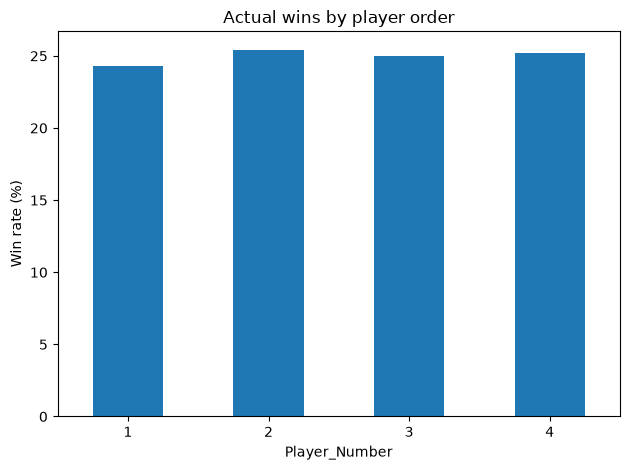

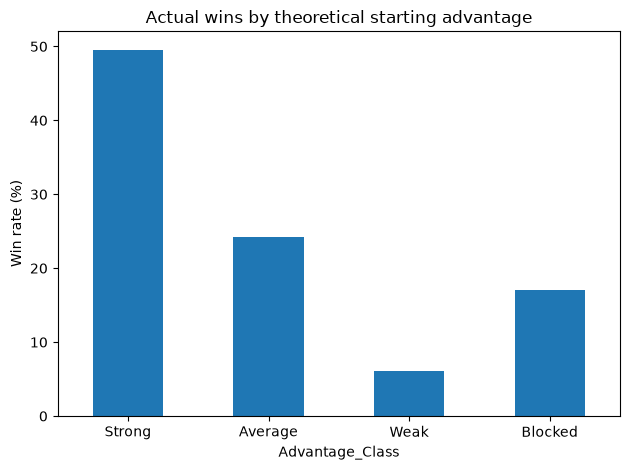

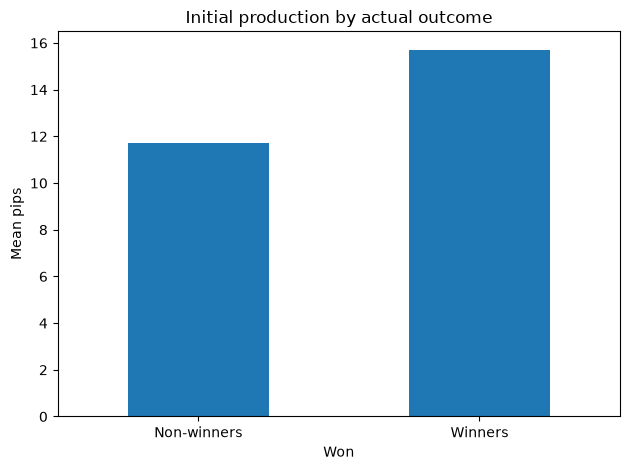

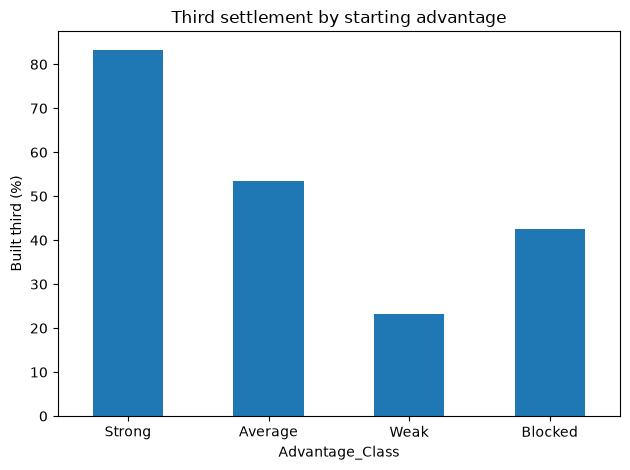

In [3]:
def chart(series,title,ylabel,name):
    ax=series.plot.bar(rot=0)
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.figure.tight_layout()
    ax.figure.savefig(CHARTS/name)
    plt.show()
chart(d.groupby("Player_Number").Won.mean()*100,"Actual wins by player order","Win rate (%)","win_by_order.svg")
chart(summary.Win_Rate*100,"Actual wins by theoretical starting advantage","Win rate (%)","win_by_advantage.svg")
chart(d.groupby("Won").Total_Production.mean().rename(index={0:"Non-winners",1:"Winners"}),"Initial production by actual outcome","Mean pips","production_vs_outcome.svg")
chart(summary.Third_Rate*100,"Third settlement by starting advantage","Built third (%)","third_by_advantage.svg")

Paired records: 10012
Pearson correlation: 0.4065152848699666
Observed median personal rolls among builders: 51.0


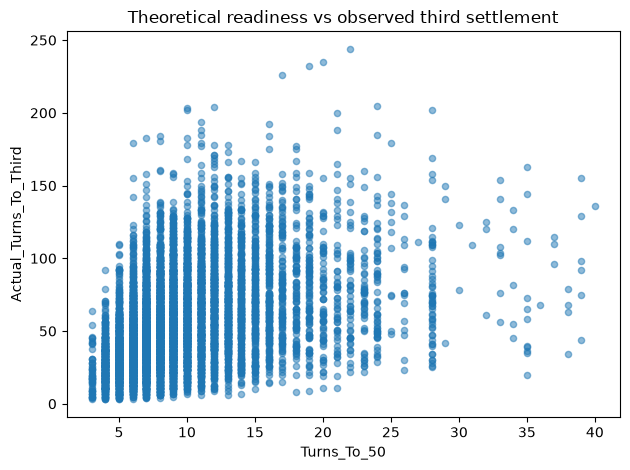

In [4]:
paired=d.dropna(subset=["Turns_To_50","Actual_Turns_To_Third"])
print("Paired records:",len(paired))
print("Pearson correlation:",paired.Turns_To_50.corr(paired.Actual_Turns_To_Third))
print("Observed median personal rolls among builders:",d.Actual_Turns_To_Third.median())
ax=paired.plot.scatter(x="Turns_To_50",y="Actual_Turns_To_Third",alpha=.5)
ax.set_title("Theoretical readiness vs observed third settlement")
ax.figure.tight_layout(); ax.figure.savefig(CHARTS/"readiness_vs_actual.svg"); plt.show()

The scatterplot excludes players with no observed third settlement or no finite modeled threshold; it is conditional on both outcomes. Game termination is a competing event; the missing timing is not zero. The actual third settlement can use more roads, ports and development cards, so the theoretical and observed targets differ.

,Model,Accuracy,Balanced_Accuracy,ROC_AUC,Within_Game_Top1
0,Uniform baseline,0.750000,0.500000,0.500000,0.250000
1,Placement order,0.750000,0.500000,0.496355,0.244093
2,Production only,0.770124,0.593445,0.764713,0.531988
3,Initial features,0.775631,0.602723,0.779758,0.548458
4,Initial + readiness,0.777683,0.614304,0.785057,0.561474


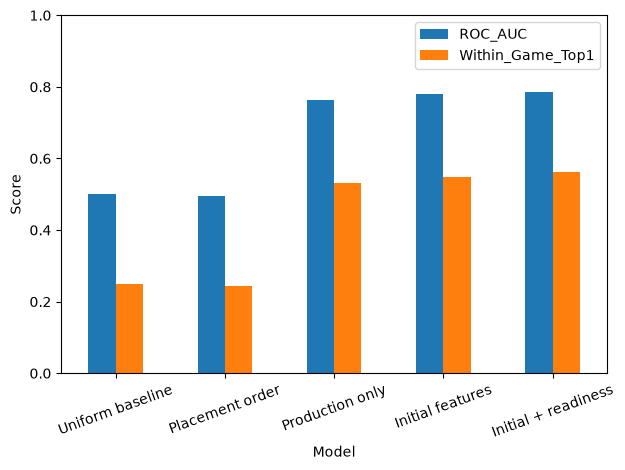

In [5]:
metrics,pred=compare(d)
display(metrics)
metrics.to_csv(OUT/"outcome_prediction_results.csv",index=False)
pred.to_csv(OUT/"outcome_predictions.csv",index=False)
ax=metrics.set_index("Model")[["ROC_AUC","Within_Game_Top1"]].plot.bar(rot=20)
ax.set_ylim(0,1); ax.set_ylabel("Score")
ax.figure.tight_layout(); ax.figure.savefig(CHARTS/"prediction_comparison.svg"); plt.show()

Five folds split by whole games using sorted game IDs modulo five. Each position receives an out-of-fold score from a regularized logistic model. Accuracy uses 0.5; ranking accuracy selects the highest score per game, sharing credit among exact ties. A uniform random winner guess has 25% ranking accuracy. No external validation or hyperparameter tuning is claimed.